# Identificação do projeto

**Título do projeto:** Perfil das faixas populares nos charts da Deezer por gênero  
**Integrantes do grupo:** Eduardo Fabri, João Correa, Rodrigo Alves e João Pedro Cardoso  
**Turma:** Bacharelado em Sistemas de Informação • 2º semestre de 2026  
**Descrição breve do problema ou contexto:** os charts da Deezer dizem quais faixas estão no topo de cada gênero, mas não o que elas têm em comum. Este notebook usa o conjunto preparado no RA1 para descrever e comparar, entre gêneros, a duração das faixas, a idade do lançamento, a popularidade do artista e a concentração de artistas no ranking, e testa uma previsão simples com Machine Learning.

---

# RA3 — Analysis, Visualization and Machine Learning

Utilize os dados preparados e processados nas etapas anteriores para produzir análises estatísticas, visualizações e interpretações que contribuam para responder ao problema definido. Explore também uma aplicação simples de Machine Learning, por classificação ou regressão, para investigar uma possibilidade de previsão a partir dos dados.

## 1. Análise estatística descritiva

Realize uma análise estatística dos dados, contemplando:

- **Tendência central:** utilização de média e/ou mediana para compreender valores representativos.
- **Dispersão:** utilização de medidas como amplitude ou desvio-padrão para analisar a variabilidade.
- **Distribuição:** investigação da frequência, concentração ou distribuição dos valores.

As medidas utilizadas devem ser coerentes com as características dos dados e com o problema investigado. Apresente os resultados e explique o que eles representam no contexto do projeto.

In [1]:
# Preparação do ambiente: bibliotecas, pastas do projeto e origem dos dados
import subprocess
import sys
from pathlib import Path

import pandas as pd

URL_REPOSITORIO = "https://github.com/Jcliz/machine-learning-ra3.git"
PASTA_CLONE = "machine-learning-ra3"
RAMO = "main"  # no Colab, troque pelo ramo do repositório que quiser executar
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    if Path(PASTA_CLONE).exists():
        # Clone de uma execução anterior nesta sessão do Colab: traz a versão mais nova do ramo
        subprocess.run(["git", "-C", PASTA_CLONE, "pull", "-q", "origin", RAMO], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "-b", RAMO, URL_REPOSITORIO], check=True)

# O conjunto preparado fica em dados/ no repositório da entrega e em dados/preparados/ no de desenvolvimento
candidatos = [Path(PASTA_CLONE), Path.cwd(), Path.cwd().parent]
encontrados = [
    (p.resolve(), arquivo.resolve())
    for p in candidatos if (p / "requirements.txt").exists()
    for arquivo in (p / "dados" / "faixas_preparadas.csv", p / "dados" / "preparados" / "faixas_preparadas.csv")
    if arquivo.exists()
]
if not encontrados:
    raise FileNotFoundError(
        "Conjunto preparado não encontrado (dados/faixas_preparadas.csv ao lado do requirements.txt). "
        f"Rode o notebook de dentro do clone (raiz ou notebook/) ou, no Colab, confira o ramo '{RAMO}'."
    )
RAIZ, ARQUIVO_PREPARADO = encontrados[0]
PASTA_PREPARADOS = ARQUIVO_PREPARADO.parent

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
print(f"Raiz do projeto: {RAIZ.name}")  # só o nome da pasta: o caminho completo é da máquina de quem executa
print(f"Ambiente: {'Google Colab' if NO_COLAB else 'local'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

Raiz do projeto: data-analytics
Ambiente: local · Python 3.13.18 · pandas 2.3.3


In [2]:
# Releitura do conjunto preparado para a análise
colunas_inteiras_analise = ["id_faixa", "id_chart", "posicao_chart", "id_artista", "id_album",
                            "duracao_s", "rank", "numero_fas"]
colunas_texto_analise = ["titulo", "genero", "tipo_chart", "artista"]
colunas_booleanas_analise = ["lancamento_posterior_coleta", "duracao_fora_limites_iqr"]
df_analise = pd.read_csv(
    ARQUIVO_PREPARADO, encoding="utf-8",
    dtype={**{c: "int64" for c in colunas_inteiras_analise},
           **{c: "string" for c in colunas_texto_analise},
           **{c: "bool" for c in colunas_booleanas_analise}},
    parse_dates=["data_lancamento", "data_coleta"],
)
print(f"{len(df_analise)} ocorrências faixa-chart, {df_analise['id_faixa'].nunique()} faixas distintas, "
      f"{df_analise.loc[df_analise['tipo_chart'].eq('genero'), 'genero'].nunique()} charts de gênero "
      f"e {df_analise['tipo_chart'].eq('geral').sum()} ocorrências no chart geral.")

2800 ocorrências faixa-chart, 2581 faixas distintas, 27 charts de gênero e 100 ocorrências no chart geral.


In [3]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 2. Visualização e interpretação dos dados

Produza pelo menos três visualizações que contribuam para compreender diferentes características dos dados. As visualizações deverão:

- Ser adequadas às informações apresentadas.
- Possuir identificação clara das variáveis e dos resultados.
- Ser acompanhadas de uma breve interpretação.

Identifique padrões, tendências, diferenças ou comportamentos relevantes, evitando limitar a análise à simples apresentação de gráficos.

In [4]:
# Recorte e convenções das visualizações
from inspect import signature as assinatura
from math import ceil as arredondar_para_cima

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from IPython.display import display

# Cada gráfico usa somente o conjunto relido na seção 1, sem depender de outras medidas.
df_generos_vis = df_analise.loc[df_analise["tipo_chart"].eq("genero")].copy()
df_geral_vis = df_analise.loc[df_analise["tipo_chart"].eq("geral")].copy()
data_retrato_vis = df_analise["data_coleta"].min().strftime("%d/%m/%Y")
estilo_vis = {
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
}
print(f"Comparações por gênero: {len(df_generos_vis)} ocorrências faixa-chart, "
      f"{df_generos_vis['genero'].nunique()} charts. "
      f"Referência geral separada: {len(df_geral_vis)} ocorrências.")

Comparações por gênero: 2700 ocorrências faixa-chart, 27 charts. Referência geral separada: 100 ocorrências.


**Resposta do grupo:**

Os gráficos comparam as músicas que estavam no topo dos charts na data da coleta. Se uma música aparece em dois charts, ela entra nas duas comparações. São 2.700 registros nos charts de gênero e 100 no chart geral, que é mostrado separadamente na P3. Cada registro representa uma faixa em um chart. Fonte: seção 2, célula "Recorte e convenções das visualizações".

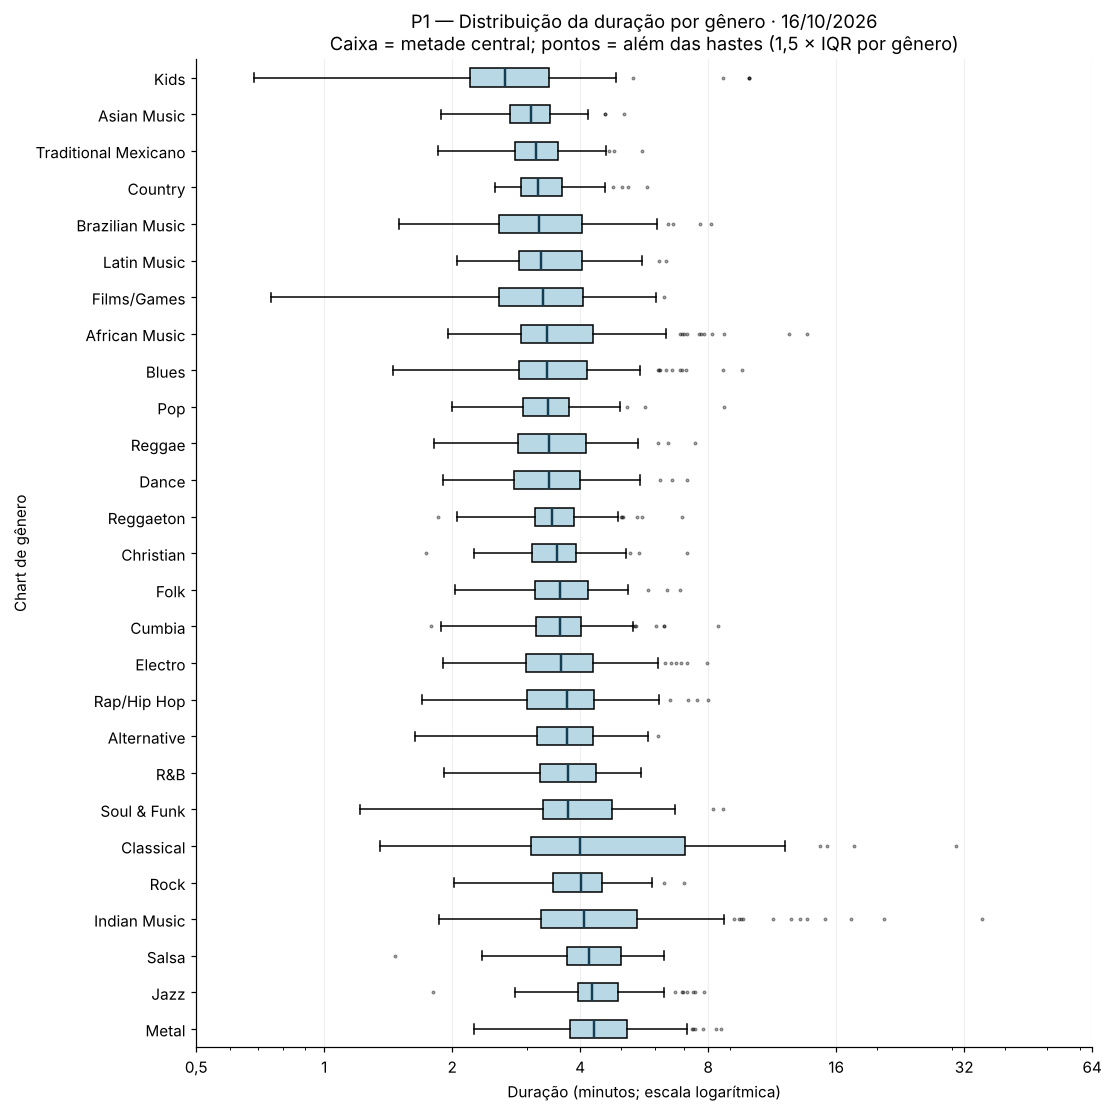

,ocorrencias,mediana_min,inicio_caixa_min,fim_caixa_min,maximo_min
genero,,,,,
Kids,100,2.66,2.20,3.38,9.98
Asian Music,100,3.07,2.73,3.40,5.08
Traditional Mexicano,100,3.14,2.82,3.55,5.60
Country,100,3.18,2.90,3.62,5.75
Brazilian Music,100,3.19,2.58,4.03,8.12
Latin Music,100,3.24,2.87,4.03,6.35
Films/Games,100,3.28,2.58,4.06,6.28
African Music,100,3.34,2.91,4.29,13.68
Blues,100,3.35,2.87,4.14,9.63


In [5]:
# Duração por gênero (boxplot)
resumo_duracao_vis = (
    df_generos_vis.groupby("genero")["duracao_s"]
    .agg(ocorrencias="size", mediana_s="median", minimo_s="min", maximo_s="max")
    .sort_values("mediana_s")
)
quartis_duracao_vis = df_generos_vis.groupby("genero")["duracao_s"].quantile([0.25, 0.75]).unstack()
resumo_duracao_vis["mediana_min"] = resumo_duracao_vis["mediana_s"] / 60
resumo_duracao_vis["inicio_caixa_min"] = quartis_duracao_vis[0.25] / 60
resumo_duracao_vis["fim_caixa_min"] = quartis_duracao_vis[0.75] / 60
resumo_duracao_vis["maximo_min"] = resumo_duracao_vis["maximo_s"] / 60
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    duracoes_vis = [
        df_generos_vis.loc[df_generos_vis["genero"].eq(genero_vis), "duracao_s"] / 60
        for genero_vis in resumo_duracao_vis.index
    ]
    # Compatibilidade com matplotlib 3.8 e com a orientação nomeada das versões recentes.
    orientacao_vis = ({"orientation": "horizontal"} if "orientation" in assinatura(eixo_vis.boxplot).parameters
                      else {"vert": False})
    caixas_vis = eixo_vis.boxplot(
        duracoes_vis, **orientacao_vis, patch_artist=True, whis=1.5,
        medianprops={"color": "#153e52", "linewidth": 1.6},
        flierprops={"marker": ".", "markersize": 3, "alpha": 0.5},
    )
    for caixa_vis in caixas_vis["boxes"]:
        caixa_vis.set_facecolor("#b8d8e5")
    eixo_vis.set_yticks(range(1, len(resumo_duracao_vis) + 1), resumo_duracao_vis.index)
    eixo_vis.invert_yaxis()
    eixo_vis.set_xscale("log")
    eixo_vis.set_xticks([0.5, 1, 2, 4, 8, 16, 32, 64])
    eixo_vis.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ",")))
    eixo_vis.set_xlabel("Duração (minutos; escala logarítmica)")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P1 — Distribuição da duração por gênero · {data_retrato_vis}\n"
                       "Caixa = metade central; pontos = além das hastes (1,5 × IQR por gênero)")
    eixo_vis.grid(axis="x", alpha=0.2)
    plt.show()
display(resumo_duracao_vis[["ocorrencias", "mediana_min", "inicio_caixa_min", "fim_caixa_min", "maximo_min"]].round(2))

**Interpretação — P1:** a duração típica das músicas muda de um gênero para outro. Em Kids, a duração do meio da lista é de aproximadamente 2 minutos e 40 segundos; em Metal, é de 4 minutos e 19 segundos. Isso não significa que toda música de Metal seja mais longa que qualquer música de Kids: há músicas de durações diferentes dentro de cada gênero, como mostram as caixas e os pontos.

Classical tem maior variação na metade central das músicas, que vai de cerca de 3 minutos e 4 segundos a 7 minutos e 4 segundos. Em Asian Music, essa parte fica entre 2 minutos e 44 segundos e 3 minutos e 24 segundos. A caixa mais larga mostra essa diferença de durações dentro do próprio gênero.

Os pontos são músicas que ficam além das hastes da caixa, pela regra de 1,5 vez o intervalo entre o primeiro e o terceiro quartil (IQR). São durações mais afastadas do centro, que não indicam erro por si só. Esses limites são calculados por gênero e não precisam coincidir com a sinalização de qualidade já gravada no conjunto preparado.

As medianas são 159,5 s em Kids e 258,5 s em Metal, com 100 faixas em cada chart. A faixa mais longa dos charts de gênero tem 2.120 s (35 minutos e 20 segundos), em Indian Music. Ela foi mantida, mas esse caso isolado não resume o gênero inteiro. Fonte: seção 2, célula "Duração por gênero (boxplot)".

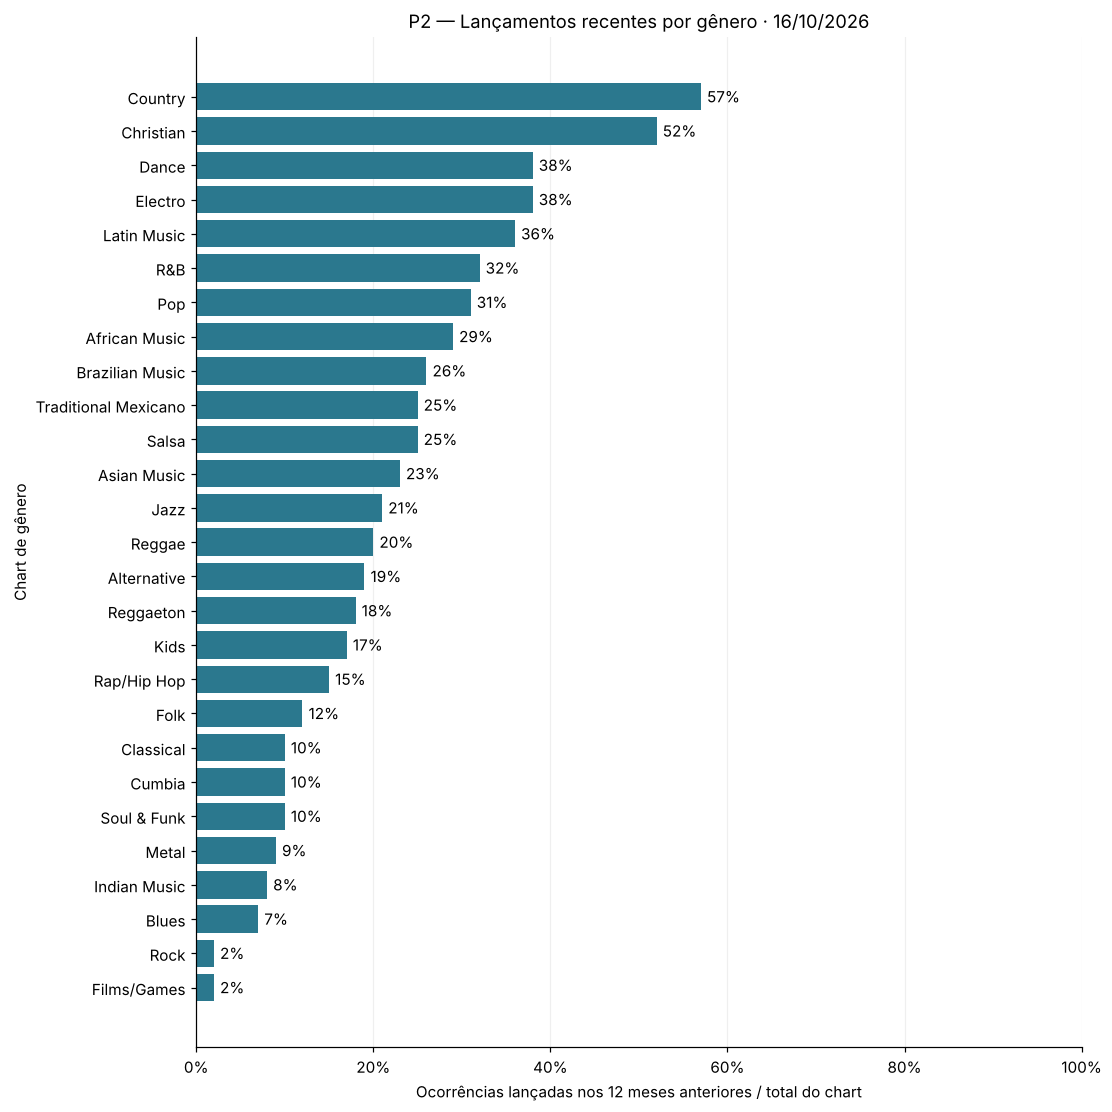

,recentes,ocorrencias,percentual
genero,,,
Films/Games,2,100,2.0
Rock,2,100,2.0
Blues,7,100,7.0
Indian Music,8,100,8.0
Metal,9,100,9.0
Soul & Funk,10,100,10.0
Cumbia,10,100,10.0
Classical,10,100,10.0
Folk,12,100,12.0


Janela inclusiva: 16/10/2025 a 16/10/2026.
Recentes: 592 de 2700 ocorrências. Lançamentos posteriores à coleta, fora do numerador: 1.


In [6]:
# Lançamentos nos 12 meses anteriores à coleta
inicio_janela_vis = df_generos_vis["data_coleta"] - pd.DateOffset(months=12)
df_generos_vis["recente_vis"] = (
    df_generos_vis["data_lancamento"].ge(inicio_janela_vis)
    & ~df_generos_vis["lancamento_posterior_coleta"]
)
resumo_recentes_vis = (
    df_generos_vis.groupby("genero")["recente_vis"]
    .agg(recentes="sum", ocorrencias="size")
)
resumo_recentes_vis["percentual"] = (
    100 * resumo_recentes_vis["recentes"] / resumo_recentes_vis["ocorrencias"]
)
resumo_recentes_vis = resumo_recentes_vis.sort_values("percentual")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(resumo_recentes_vis.index, resumo_recentes_vis["percentual"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.0f}%" for valor in resumo_recentes_vis["percentual"]], padding=4,
    )
    eixo_vis.set_xlim(0, 100)
    eixo_vis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    eixo_vis.set_xlabel("Ocorrências lançadas nos 12 meses anteriores / total do chart")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P2 — Lançamentos recentes por gênero · {data_retrato_vis}")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(resumo_recentes_vis)
print(f"Janela inclusiva: {inicio_janela_vis.min():%d/%m/%Y} a {df_generos_vis['data_coleta'].max():%d/%m/%Y}.")
print(f"Recentes: {df_generos_vis['recente_vis'].sum()} de {len(df_generos_vis)} ocorrências. "
      f"Lançamentos posteriores à coleta, fora do numerador: "
      f"{df_generos_vis['lancamento_posterior_coleta'].sum()}.")

**Interpretação — P2:** alguns charts têm mais espaço para músicas lançadas recentemente. Em Country, mais da metade das faixas foi lançada no último ano: 57 de 100. Em Rock e Films/Games, foram apenas 2 de 100 em cada chart. Portanto, estar no topo não significa necessariamente ser uma novidade; o peso dos lançamentos recentes varia entre os gêneros.

Ao todo, 592 dos 2.700 registros de faixas nos charts de gênero (21,9%) são lançamentos entre 16/10/2025 e 16/10/2026, incluindo essas duas datas. A única faixa com lançamento posterior à coleta continua no total do seu chart, mas não conta como lançamento já ocorrido. Essa comparação descreve a idade dos lançamentos na coleta, sem acompanhar entradas e saídas dos charts ao longo do tempo. Fonte: seção 2, célula "Lançamentos nos 12 meses anteriores à coleta".

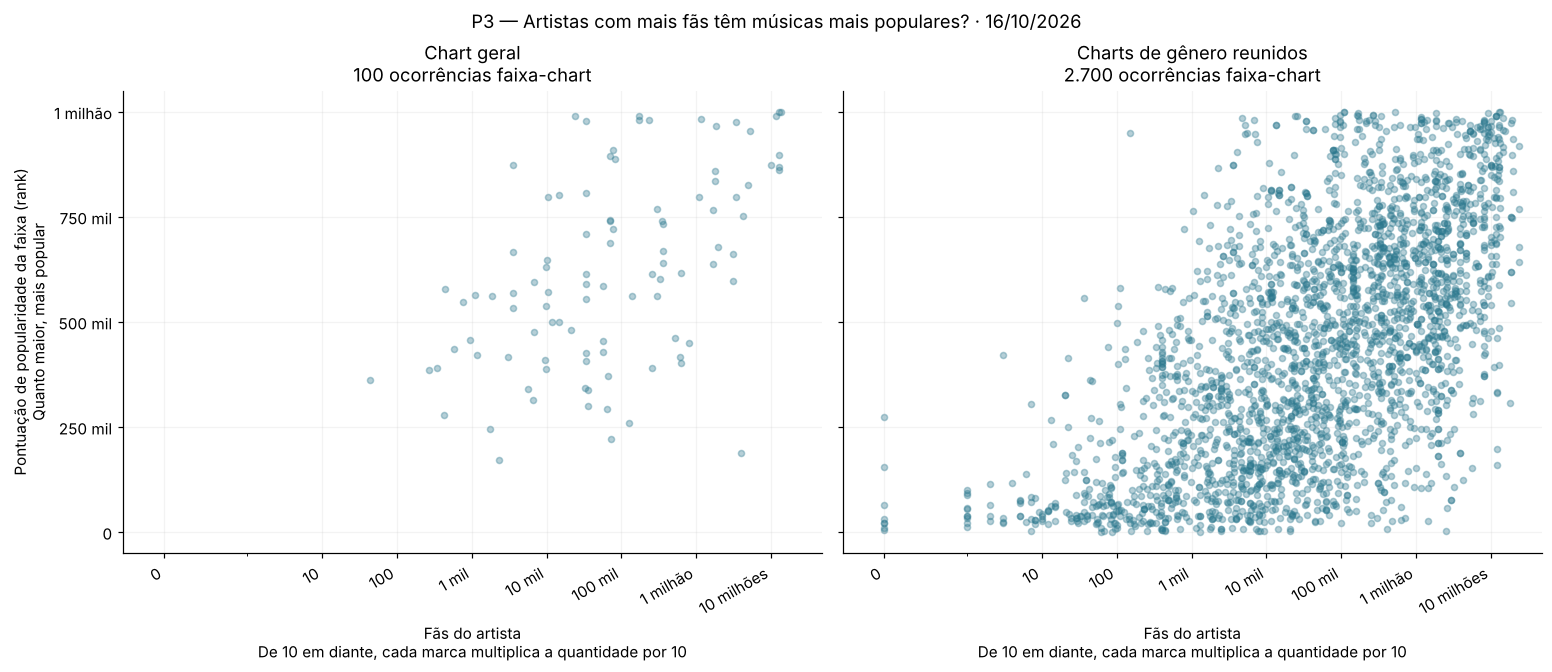

,recorte,ocorrencias,fas_iguais_zero,spearman
0,Chart geral,100,0,0.530
1,Charts de gênero reunidos,2700,8,0.601


In [7]:
# Fãs do artista e popularidade: chart geral e conjunto dos gêneros
# Spearman equivale à correlação de Pearson dos postos, com postos médios nos empates.
correlacoes_gerais_vis = []
limite_popularidade_vis = max(100_000, arredondar_para_cima(df_analise["rank"].max() / 100_000) * 100_000)
marcacoes_popularidade_vis = [limite_popularidade_vis * parte_vis / 4 for parte_vis in range(5)]
rotulos_popularidade_vis = [
    ("0" if valor_vis == 0 else
     f"{valor_vis / 1_000_000:g} milhão" if valor_vis == 1_000_000 else
     f"{valor_vis / 1_000_000:g} milhões" if valor_vis > 1_000_000 else
     f"{valor_vis / 1_000:g} mil").replace(".", ",")
    for valor_vis in marcacoes_popularidade_vis
]
with plt.rc_context(estilo_vis):
    figura_vis, eixos_vis = plt.subplots(1, 2, figsize=(14, 6), sharey=True, layout="constrained")
    for eixo_vis, (nome_vis, recorte_vis) in zip(
        eixos_vis, [("Chart geral", df_geral_vis), ("Charts de gênero reunidos", df_generos_vis)]
    ):
        correlacao_vis = recorte_vis["numero_fas"].rank().corr(recorte_vis["rank"].rank())
        correlacoes_gerais_vis.append({
            "recorte": nome_vis, "ocorrencias": len(recorte_vis),
            "fas_iguais_zero": int(recorte_vis["numero_fas"].eq(0).sum()),
            "spearman": correlacao_vis,
        })
        eixo_vis.scatter(recorte_vis["numero_fas"], recorte_vis["rank"], s=16, alpha=0.35, color="#2b788e")
        eixo_vis.set_xscale("symlog", linthresh=1)
        eixo_vis.set_xticks(
            [0, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000],
            ["0", "10", "100", "1 mil", "10 mil", "100 mil", "1 milhão", "10 milhões"],
            rotation=30, ha="right",
        )
        # Margens na área do gráfico preservam os círculos inteiros, inclusive os de zero fãs.
        eixo_vis.set_xlim(-0.5, df_analise["numero_fas"].max() * 2)
        eixo_vis.set_ylim(-0.05 * limite_popularidade_vis, 1.05 * limite_popularidade_vis)
        eixo_vis.set_yticks(marcacoes_popularidade_vis, rotulos_popularidade_vis)
        eixo_vis.set_xlabel("Fãs do artista\nDe 10 em diante, cada marca multiplica a quantidade por 10")
        eixo_vis.set_title(f"{nome_vis}\n{len(recorte_vis):,} ocorrências faixa-chart".replace(",", "."))
        eixo_vis.grid(alpha=0.15)
    eixos_vis[0].set_ylabel("Pontuação de popularidade da faixa (rank)\nQuanto maior, mais popular")
    figura_vis.suptitle(f"P3 — Artistas com mais fãs têm músicas mais populares? · {data_retrato_vis}")
    plt.show()
display(pd.DataFrame(correlacoes_gerais_vis).round({"spearman": 3}))

In [8]:
# Exemplos de fãs e popularidade
# Exemplos observados nos charts de gênero, sem tratá-los como perfil de todo o conjunto.
exemplos_popularidade_vis = pd.concat([
    df_generos_vis.loc[df_generos_vis["numero_fas"].le(1_000)]
    .nlargest(1, "rank").assign(leitura="Poucos fãs, pontuação alta"),
    df_generos_vis.loc[df_generos_vis["numero_fas"].ge(1_000_000)]
    .nsmallest(1, "rank").assign(leitura="Muitos fãs, pontuação baixa"),
])
display(exemplos_popularidade_vis[["leitura", "genero", "artista", "titulo", "numero_fas", "rank"]])

,leitura,genero,artista,titulo,numero_fas,rank
2095,"Poucos fãs, pontuação alta",African Music,ISSAH,BADDIES IN BELGICA,150,948653
2621,"Muitos fãs, pontuação baixa",Kids,Frank Sinatra,Let It Snow! Let It Snow! Let It Snow! (with T...,2487314,2757


**Como ler:** cada bolinha representa uma faixa em um chart. Mais à direita significa mais fãs do artista; mais acima significa maior popularidade da música. Essa popularidade é a pontuação `rank` da Deezer: não é a posição de 1º ou 2º lugar, nem uma contagem de ouvintes ou reproduções. No eixo horizontal, 1 mil significa 1.000 fãs e 1 milhão significa 1.000.000. A partir de 10, cada marca multiplica a quantidade por dez, para que artistas com dezenas e com milhões de fãs caibam na mesma figura. Os pontos de zero fãs também são mantidos.

**Interpretação — P3, visão geral:** a quantidade de fãs, sozinha, não determina a popularidade da música. Ter dez vezes mais fãs não implica ter dez vezes mais popularidade. Ainda existe uma tendência no conjunto: artistas com mais fãs tendem a ter faixas mais populares. Mas há exceções, e artistas com poucos fãs também podem ter músicas muito populares.

Por exemplo, "BADDIES IN BELGICA", de ISSAH, tem 150 fãs do artista e 948.653 pontos de popularidade. A faixa de Frank Sinatra exibida na tabela tem 2.487.314 fãs do artista e 2.757 pontos. Esses dois casos ilustram por que o número de fãs não basta para prever o resultado de uma música; não dizem com que frequência as exceções acontecem.

A tendência positiva é resumida pela correlação de Spearman: 0,53 nos 100 registros do chart geral e 0,60 nos 2.700 dos charts de gênero reunidos. Esses valores medem quanto as duas ordenações caminham juntas; não significam que 53% ou 60% da popularidade seja causada pelos fãs. O retrato mostra uma associação e não permite afirmar que mais fãs causem mais popularidade. Fontes: seção 2, células "Fãs do artista e popularidade: chart geral e conjunto dos gêneros" e "Exemplos de fãs e popularidade".

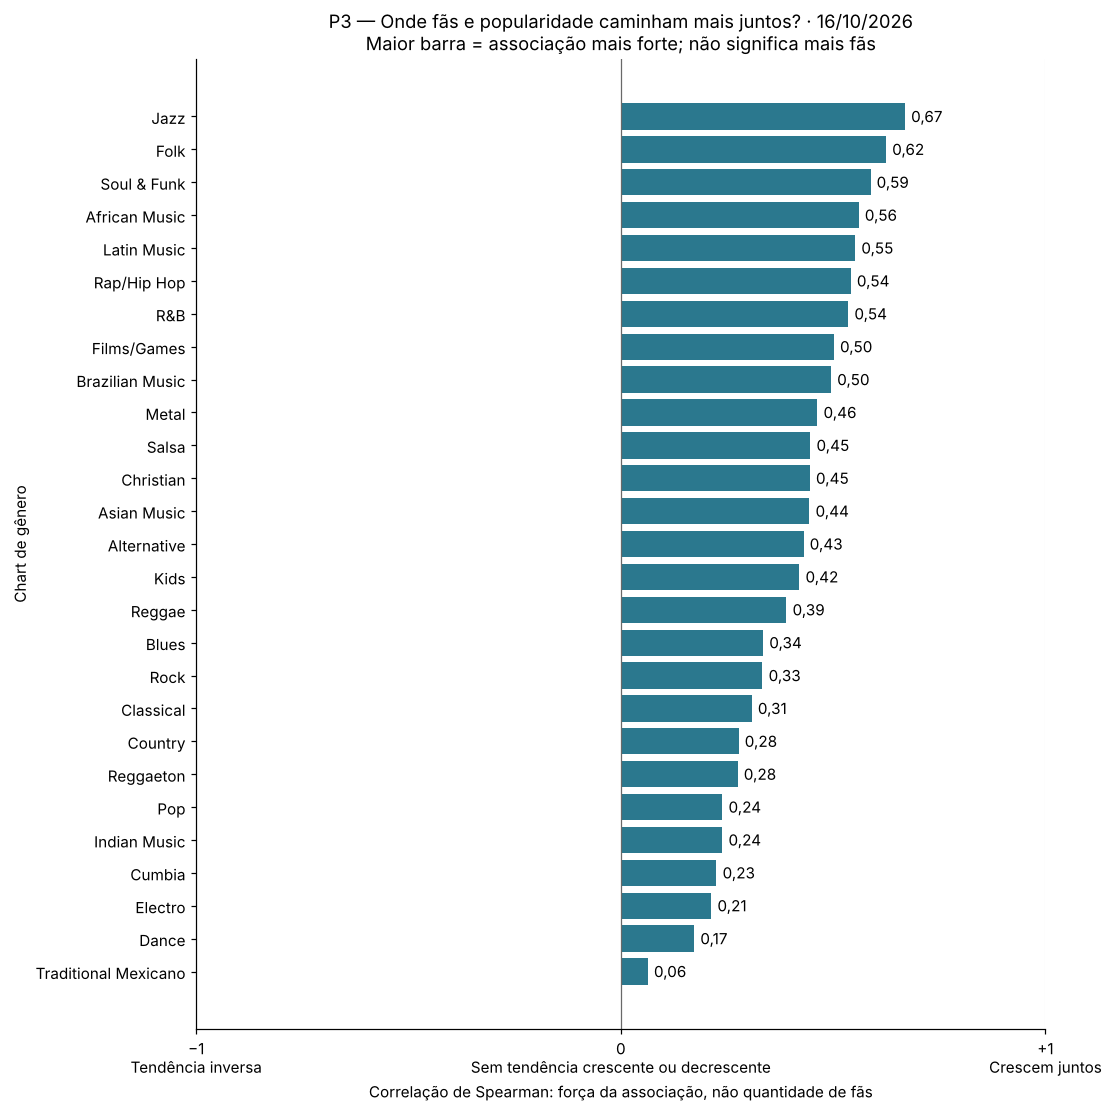

,ocorrencias,mediana_fas_por_ocorrencia,spearman
genero,,,
Traditional Mexicano,100,510083.0,0.064
Dance,100,104057.0,0.173
Electro,100,41978.0,0.213
Cumbia,100,11909.0,0.225
Indian Music,100,1258.5,0.239
Pop,100,613963.0,0.239
Reggaeton,100,1760661.0,0.275
Country,100,34805.0,0.277
Classical,100,1693.5,0.308


In [9]:
# Associação entre fãs e popularidade dentro de cada gênero
correlacoes_genero_vis = pd.DataFrame([
    {"genero": genero_vis, "ocorrencias": len(grupo_vis),
     "mediana_fas_por_ocorrencia": grupo_vis["numero_fas"].median(),
     "spearman": grupo_vis["numero_fas"].rank().corr(grupo_vis["rank"].rank())}
    for genero_vis, grupo_vis in df_generos_vis.groupby("genero")
]).set_index("genero").sort_values("spearman")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(correlacoes_genero_vis.index, correlacoes_genero_vis["spearman"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.2f}".replace(".", ",") for valor in correlacoes_genero_vis["spearman"]], padding=4,
    )
    eixo_vis.set_xlim(-1, 1)
    eixo_vis.set_xticks(
        [-1, 0, 1],
        ["−1\nTendência inversa", "0\nSem tendência crescente ou decrescente", "+1\nCrescem juntos"],
    )
    eixo_vis.axvline(0, color="dimgray", linewidth=0.8)
    eixo_vis.set_xlabel("Correlação de Spearman: força da associação, não quantidade de fãs")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P3 — Onde fãs e popularidade caminham mais juntos? · {data_retrato_vis}\n"
                       "Maior barra = associação mais forte; não significa mais fãs")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(correlacoes_genero_vis.round({"spearman": 3}))

**Interpretação — P3, por gênero:** Jazz aparece em primeiro porque, dentro desse chart, a tendência de artistas com mais fãs terem músicas mais populares é mais forte. Isso não quer dizer que Jazz tenha mais fãs que os outros gêneros. Em Traditional Mexicano, essa tendência é bem menos nítida: saber que um artista tem mais fãs ajuda pouco a acompanhar a ordem de popularidade das faixas.

A medida dessa associação é 0,67 em Jazz e 0,06 em Traditional Mexicano, considerando 100 faixas em cada chart. Quanto mais perto de +1, mais as duas ordenações caminham juntas; perto de zero, essa tendência é pouco marcada. Os 27 charts têm valores positivos neste retrato, mas nenhum chega à correspondência perfeita de +1.

A diferença entre associação e quantidade de fãs aparece também na tabela: a mediana de fãs do artista nas 100 faixas de Jazz é 778,5; nas 100 de Pop, é 613.963, embora a associação em Pop seja menor, de 0,24. Assim, estar no topo deste gráfico não significa ter o maior número de fãs. Esses resultados descrevem os charts na data da coleta e não garantem que o padrão se repita em outras datas. Fonte: seção 2, célula "Associação entre fãs e popularidade dentro de cada gênero".

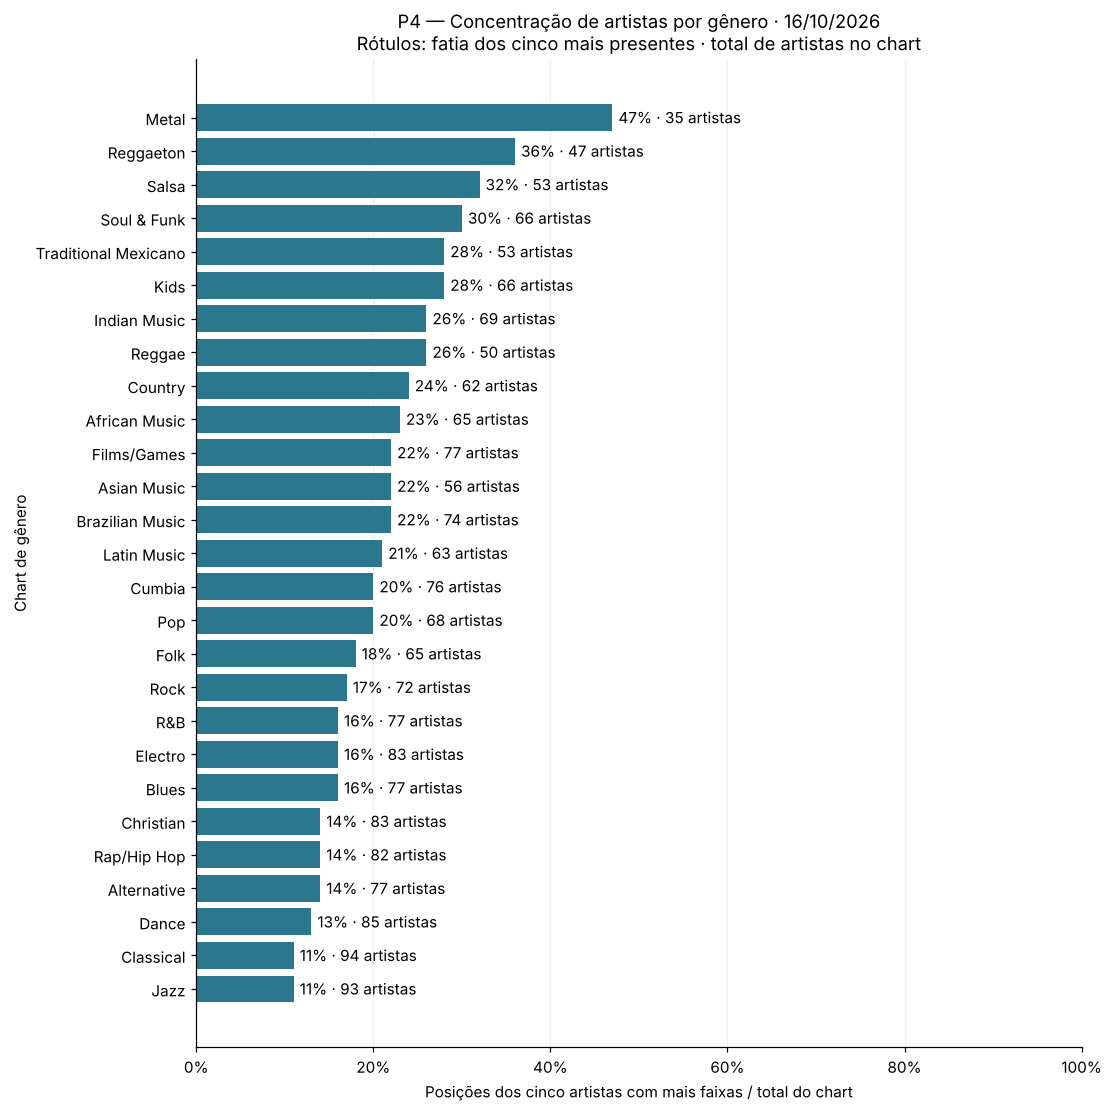

,id_chart,ocorrencias,artistas_distintos,posicoes_cinco_artistas,percentual
genero,,,,,
Jazz,129,100,93,11,11.0
Classical,98,100,94,11,11.0
Dance,113,100,85,13,13.0
Alternative,85,100,77,14,14.0
Rap/Hip Hop,116,100,82,14,14.0
Christian,186,100,83,14,14.0
Blues,153,100,77,16,16.0
Electro,106,100,83,16,16.0
R&B,165,100,77,16,16.0


In [10]:
# Concentração das posições nos cinco artistas mais presentes
contagem_artistas_vis = (
    df_generos_vis.groupby(["id_chart", "genero", "id_artista"])
    .size().rename("posicoes").reset_index()
)
# Desempate por identificador; o total das cinco maiores contagens não muda em empates.
cinco_artistas_vis = (
    contagem_artistas_vis.sort_values(["posicoes", "id_artista"], ascending=[False, True])
    .groupby(["id_chart", "genero"]).head(5)
)
resumo_concentracao_vis = df_generos_vis.groupby(["id_chart", "genero"]).agg(
    ocorrencias=("id_faixa", "size"), artistas_distintos=("id_artista", "nunique")
)
resumo_concentracao_vis["posicoes_cinco_artistas"] = (
    cinco_artistas_vis.groupby(["id_chart", "genero"])["posicoes"].sum()
)
resumo_concentracao_vis["percentual"] = (
    100 * resumo_concentracao_vis["posicoes_cinco_artistas"] / resumo_concentracao_vis["ocorrencias"]
)
resumo_concentracao_vis = resumo_concentracao_vis.reset_index().set_index("genero").sort_values("percentual")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(resumo_concentracao_vis.index, resumo_concentracao_vis["percentual"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[
            f"{linha_vis.percentual:.0f}% · {linha_vis.artistas_distintos} artistas"
            for linha_vis in resumo_concentracao_vis.itertuples()
        ], padding=4,
    )
    eixo_vis.set_xlim(0, 100)
    eixo_vis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    eixo_vis.set_xlabel("Posições dos cinco artistas com mais faixas / total do chart")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P4 — Concentração de artistas por gênero · {data_retrato_vis}\n"
                       "Rótulos: fatia dos cinco mais presentes · total de artistas no chart")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(resumo_concentracao_vis)

**Interpretação — P4:** em alguns charts, os mesmos artistas aparecem várias vezes. Em Metal, apenas cinco artistas ocupam quase metade da lista: 47 das 100 posições. Em Jazz e Classical, os cinco artistas mais presentes ocupam 11 das 100 posições em cada chart. Nesses dois casos, a lista distribui mais posições entre artistas diferentes.

Isso também aparece na quantidade de nomes: Metal tem 35 artistas distintos, Jazz tem 93 e Classical tem 94, todos em charts de 100 faixas. Portanto, listas do mesmo tamanho podem dar espaço a quantidades bem diferentes de artistas. Estamos contando posições ocupadas; o gráfico não informa a participação desses artistas nas reproduções ou na audiência. Fonte: seção 2, célula "Concentração das posições nos cinco artistas mais presentes".

## 3. Amostragem e representatividade

Apresente uma breve análise sobre a representatividade dos dados utilizados, abordando:

- A origem e a abrangência do conjunto de dados.
- Se os registros representam adequadamente o problema investigado.
- Possíveis limitações ou vieses que possam influenciar os resultados.

Não é obrigatório implementar um procedimento de amostragem. Caso utilize uma amostra, explique como os registros foram selecionados.

In [11]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 4. Aplicação de Machine Learning

Implemente uma aplicação simples de aprendizagem supervisionada, por **classificação** (prever uma categoria ou classe) ou **regressão** (estimar um valor numérico). A implementação deverá contemplar:

1. Definição do problema preditivo.
2. Identificação da variável-alvo (*target*) e das características utilizadas (*features*).
3. Separação dos dados para treinamento e teste.
4. Treinamento de um modelo e realização de previsões.
5. Avaliação dos resultados utilizando pelo menos uma métrica adequada ao problema.

Caso o conjunto de dados original não possua características adequadas para uma aplicação supervisionada, outro conjunto de dados pode ser utilizado exclusivamente nesta etapa, com uma breve justificativa.

**Resposta do grupo:**

**Problema preditivo:** regressão. A partir de atributos conhecidos da faixa e do artista, o modelo estima o `rank`, índice de popularidade que a Deezer atribui à faixa. É a pergunta P3 transformada em previsão: quanto do `rank` os fãs do artista, junto com outros atributos, conseguem explicar.

**Variável-alvo:** `rank`, na escala original, nas 2.700 ocorrências dos 27 charts de gênero (o chart geral fica de fora para não repetir as mesmas faixas em outro recorte).

**Características:** número de fãs do artista em escala logarítmica (`log_fas`, porque `numero_fas` é muito assimétrico), duração em segundos (`duracao_s`), idade da faixa na data da coleta em dias (`idade_dias`) e o gênero do chart em variáveis indicadoras. A posição no chart não entra, porque é consequência do próprio ranking, e os identificadores também não.

O conjunto original tem alvo e características adequados, então não foi usado outro conjunto de dados.

In [12]:
# Bibliotecas e semente do Machine Learning
import numpy as np
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

SEMENTE_ML = 42  # fixa a separação treino e teste e a floresta aleatória, para a execução repetir os números
print(f"scikit-learn {sklearn.__version__} · semente {SEMENTE_ML}")

scikit-learn 1.9.1 · semente 42


In [13]:
# Recorte dos charts de gênero, variável-alvo e características
df_modelo = df_analise.loc[df_analise["tipo_chart"].eq("genero")].copy()
df_modelo["log_fas"] = np.log1p(df_modelo["numero_fas"])
df_modelo["idade_dias"] = (df_modelo["data_coleta"] - df_modelo["data_lancamento"]).dt.days

def formatar(valor):
    """Número inteiro com ponto de milhar, como no texto em português."""
    return f"{valor:,.0f}".replace(",", ".")


caracteristicas_numericas = ["log_fas", "duracao_s", "idade_dias"]
indicadoras_genero = pd.get_dummies(df_modelo["genero"], prefix="genero", drop_first=True, dtype=int)
X = pd.concat([df_modelo[caracteristicas_numericas], indicadoras_genero], axis=1)
y = df_modelo["rank"]

print(f"{len(X)} ocorrências, {X.shape[1]} características "
      f"({len(caracteristicas_numericas)} numéricas e {indicadoras_genero.shape[1]} indicadoras de gênero)")
print(f"Alvo rank: mínimo {formatar(y.min())}, mediana {formatar(y.median())}, máximo {formatar(y.max())}")
print(f"Faixas com lançamento posterior à coleta (idade negativa): {df_modelo['idade_dias'].lt(0).sum()}")

2700 ocorrências, 29 características (3 numéricas e 26 indicadoras de gênero)
Alvo rank: mínimo 807, mediana 439.398, máximo 999.724
Faixas com lançamento posterior à coleta (idade negativa): 1


In [14]:
# Separação treino e teste agrupada por faixa
separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE_ML)
indices_treino, indices_teste = next(separador.split(X, y, groups=df_modelo["id_faixa"]))
X_treino, X_teste = X.iloc[indices_treino], X.iloc[indices_teste]
y_treino, y_teste = y.iloc[indices_treino], y.iloc[indices_teste]

faixas_treino = set(df_modelo["id_faixa"].iloc[indices_treino])
faixas_teste = set(df_modelo["id_faixa"].iloc[indices_teste])
print(f"Treino: {len(X_treino)} ocorrências ({len(faixas_treino)} faixas) · "
      f"teste: {len(X_teste)} ocorrências ({len(faixas_teste)} faixas)")
print(f"Faixas presentes nos dois lados: {len(faixas_treino & faixas_teste)}")

Treino: 2163 ocorrências (2062 faixas) · teste: 537 ocorrências (516 faixas)
Faixas presentes nos dois lados: 0


In [15]:
# Treinamento dos modelos e previsões no teste
modelos = {
    "Linha de base (mediana do treino)": DummyRegressor(strategy="median"),
    "Regressão linear": LinearRegression(),
    "Floresta aleatória (comparação)": RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                             random_state=SEMENTE_ML, n_jobs=-1),
}
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes[nome] = modelo.predict(X_teste)
print(f"{len(modelos)} modelos treinados com {len(X_treino)} ocorrências; "
      f"{len(X_teste)} previsões por modelo no teste.")

3 modelos treinados com 2163 ocorrências; 537 previsões por modelo no teste.


In [16]:
# Avaliação no teste: erro absoluto médio (MAE) e coeficiente de determinação (R²)
metricas = pd.DataFrame(
    {nome: {"MAE": mean_absolute_error(y_teste, p), "R²": r2_score(y_teste, p)} for nome, p in previsoes.items()}
).T
mae_base = metricas.loc["Linha de base (mediana do treino)", "MAE"]
metricas["Redução do MAE frente à linha de base (%)"] = (1 - metricas["MAE"] / mae_base) * 100
metricas.round({"MAE": 0, "R²": 3, "Redução do MAE frente à linha de base (%)": 1})

,MAE,R²,Redução do MAE frente à linha de base (%)
Linha de base (mediana do treino),227294.0,-0.000,0.0
Regressão linear,147956.0,0.521,34.9
Floresta aleatória (comparação),144687.0,0.539,36.3


In [17]:
# Previsões da regressão linear: amostra de valores reais e previstos no teste
previsto_linear = previsoes["Regressão linear"]
amostra_previsoes = df_modelo.iloc[indices_teste][["titulo", "artista", "genero", "numero_fas", "rank"]].copy()
amostra_previsoes["rank_previsto"] = previsto_linear.round().astype(int)
amostra_previsoes["erro"] = amostra_previsoes["rank_previsto"] - amostra_previsoes["rank"]
amostra_previsoes.sample(8, random_state=SEMENTE_ML).reset_index(drop=True)

,titulo,artista,genero,numero_fas,rank,rank_previsto,erro
0,The Other Side (from Trolls World Tour),SZA,Kids,1337867,641541,576691,-64850
1,Two of Hearts,Stacey Q,Dance,2670,545613,443135,-102478
2,No Business,Durand Bernarr,Soul & Funk,3668,183483,291385,107902
3,Let Me Be In Your Arms,Sonny Fodera,Dance,32279,663010,564280,-98730
4,30 y Pico: Una Lagrima y un Recuerdo / Quizás ...,Grupo Miramar,Cumbia,12909,290433,299178,8745
5,Something Just Like This,Coldplay,Dance,18422117,546034,746037,200003
6,La Cumbia de los Monjes,Ritmo Y Sabor,Cumbia,3174,473104,285063,-188041
7,CAMBIARÉ,Luis Fonsi,Latin Music,3150306,651995,634004,-17991


In [18]:
# Coeficientes da regressão linear nas características numéricas
regressao = modelos["Regressão linear"]
coeficientes = pd.Series(regressao.coef_, index=X.columns)
efeito_fas_10x = coeficientes["log_fas"] * np.log(10)  # dez vezes mais fãs somam log(10) ao log_fas
print("Coeficientes (mudança no rank previsto por unidade, com as demais características fixas):")
print(coeficientes[caracteristicas_numericas].round(1).to_string())
print(f"Artista com 10 vezes mais fãs: rank previsto {formatar(efeito_fas_10x)} maior")
print(f"Cada minuto a mais de duração: rank previsto {formatar(coeficientes['duracao_s'] * 60)}")
print(f"Cada ano a mais de idade: rank previsto {formatar(coeficientes['idade_dias'] * 365)}")

Coeficientes (mudança no rank previsto por unidade, com as demais características fixas):
log_fas       32522.1
duracao_s      -122.0
idade_dias       -5.4
Artista com 10 vezes mais fãs: rank previsto 74.885 maior
Cada minuto a mais de duração: rank previsto -7.320
Cada ano a mais de idade: rank previsto -1.980


In [19]:
# Contribuição de cada grupo de características: regressões lineares com os mesmos treino e teste
colunas_genero = list(indicadoras_genero.columns)
grupos_caracteristicas = {
    "Todas as características": list(X.columns),
    "Só log_fas": ["log_fas"],
    "Só as indicadoras de gênero": colunas_genero,
    "Só duracao_s e idade_dias": ["duracao_s", "idade_dias"],
    "Todas, exceto log_fas": [c for c in X.columns if c != "log_fas"],
    "Todas, exceto o gênero": caracteristicas_numericas,
}
contribuicao = pd.DataFrame(
    {nome: {"Características": len(colunas),
            "R² no teste": r2_score(y_teste, LinearRegression().fit(X_treino[colunas], y_treino)
                                    .predict(X_teste[colunas]))}
     for nome, colunas in grupos_caracteristicas.items()}
).T
contribuicao["Características"] = contribuicao["Características"].astype(int)
contribuicao.round({"R² no teste": 3})

,Características,R² no teste
Todas as características,29,0.521
Só log_fas,1,0.376
Só as indicadoras de gênero,26,0.389
Só duracao_s e idade_dias,2,0.021
"Todas, exceto log_fas",28,0.398
"Todas, exceto o gênero",3,0.392


**Resposta do grupo:**

**Métricas:** erro absoluto médio (MAE), na mesma unidade do `rank`, e coeficiente de determinação (R²), a fração da variação do `rank` que o modelo explica. Ambas foram medidas nas 537 ocorrências de teste (516 faixas que o modelo não viu no treino; nenhuma faixa ficou nos dois lados).

**Desempenho:** a regressão linear erra em média 147.956 pontos de `rank`, contra 227.294 de uma linha de base que prevê sempre a mediana do treino, uma redução de 34,9%. O R² de 0,521 indica que o modelo explica cerca de metade da variação do `rank`. A floresta aleatória, usada só para comparar, chega a MAE de 144.687 e R² de 0,539: o ganho pequeno sugere que a relação é quase toda linear e que a regressão linear, mais fácil de explicar, basta.

**Contribuição das características:** o R² de 0,521 é do modelo com as 29 características juntas, e não só dos fãs. Com os mesmos treino e teste, `log_fas` sozinho chega a R² de 0,376, as indicadoras de gênero sozinhas a 0,389, e duração e idade juntas a apenas 0,021. Tirar `log_fas` do modelo completo baixa o R² para 0,398, e tirar o gênero baixa para 0,392. Os fãs do artista e o gênero do chart contribuem de forma parecida e complementar, e duração e idade quase nada acrescentam.

**Interpretação:** o coeficiente de `log_fas` é uma associação ajustada pelas demais características, e não um efeito causal: entre faixas do mesmo gênero, com a mesma duração e a mesma idade, a de um artista com 10 vezes mais fãs tem `rank` previsto 74.885 maior. Isso reforça a relação da P3 dentro de cada gênero. Metade da variação fica sem explicação, e a tabela de previsões mostra erros de até cerca de 200 mil pontos, como o de Coldplay, superestimado pelo número de fãs. Isso é esperado, já que a fórmula do `rank` da Deezer não é publicada e depende de reproduções recentes que o conjunto não tem. O modelo serve para mostrar quanto da popularidade os atributos disponíveis explicam juntos, e não para prever com precisão o `rank` de uma faixa.

## 5. Conclusões do RA3

Apresente uma conclusão geral do RA3, contemplando:

- Principais resultados identificados nas análises estatísticas e nas visualizações.
- Interpretação do desempenho do modelo de Machine Learning.
- Limitações dos dados e das análises realizadas.
- Relação dos resultados com o problema definido no projeto.

**Resposta do grupo:**

[Preencha aqui.]